# 2.2 — The Effect of Diversification on Portfolio Risk

**Learning objective:** Understand how portfolio volatility changes as more assets are added, and distinguish diversifiable risk from common risk.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("ggplot")

## 1. The effect of diversification

For a portfolio with two assets:

$$\sigma_P^2=w_1^2\sigma_1^2+w_2^2\sigma_2^2+2w_1w_2\sigma_{12}.$$

For $n$ assets:

$$\sigma_P^2=\sum_{i=1}^n w_i^2\sigma_i^2+\sum_{i=1}^n\sum_{j\ne i}w_iw_j\sigma_{ij}.$$

For an **equally weighted** portfolio, $w_i=1/n$, so:

$$\sigma_P^2=\frac{1}{n^2}\sum_{i=1}^n\sigma_i^2+\frac{1}{n^2}\sum_{i=1}^n\sum_{j\ne i}\sigma_{ij}.$$

Define the average individual variance $\bar V$ and average covariance between distinct stocks $\bar C$:

$$\bar V=\frac{1}{n}\sum_{i=1}^n\sigma_i^2,\qquad \bar C=\frac{1}{n(n-1)}\sum_{i=1}^n\sum_{j\ne i}\sigma_{ij}.$$

Then:

$$\sigma_P^2=\frac{\bar V}{n}+\left(1-\frac{1}{n}\right)\bar C.$$

If $\bar V$ and $\bar C$ remain stable as the number of assets grows, portfolio variance approaches $\bar C$. This illustrates the limit to diversification under these assumptions: common risk cannot be eliminated merely by adding stocks.

## 2. Client assignment — How much diversification is enough?

You work as a **financial adviser at a wealth-management firm**. A client currently holds a small portfolio of US stocks and wants to know whether investing in many more S&P 500 companies will meaningfully reduce risk.

The client asks:

> "If I keep adding stocks, will my portfolio keep getting safer? At what point does the extra diversification benefit become small?"

**Your task:** Prepare an evidence-based risk analysis using the supplied S&P 500 stock-price dataset.

1. **Prepare the data.** Load daily adjusted prices, align dates, handle missing values, and calculate daily log returns.
2. **Build portfolios.** Start with the first **two stocks** in the dataset and add one more stock at each step. Use **equal weights** in every portfolio.
3. **Measure risk.** Calculate the **annualized volatility** for each portfolio using the standard deviation of its daily returns and $\sqrt{252}$.
4. **Visualize the results.** Plot volatility against the **number of stocks** in the portfolio. Produce a second graph focusing on the first 50 portfolio sizes.
5. **Compare against a reference.** Calculate the mean covariance between distinct stocks and, if positive, its implied annual volatility. Explain why this is an illustration rather than an exact estimate of systematic risk.
6. **Advise your client.** Explain whether additional stocks appear to offer diminishing risk reductions, and mention at least two limitations of your historical analysis.

**Important:** Keep the stock order fixed throughout the experiment. The exercise is about the effect of adding stocks in a given order, not finding an optimal subset.

### 2.1 Load the data

The original notebook combined a Yahoo Finance download with a local Excel import, which overwrote the first dataset. For a consistent class exercise, the **supplied Excel file** is used here. Update the path if needed.

In [3]:
data_path = Path("data/SP500_comp_data.xlsx")
if not data_path.exists():
    data_path = Path("../data/SP500_comp_data.xlsx")

prices = pd.read_excel(data_path, index_col="Date")
prices.index = pd.to_datetime(prices.index)
prices = prices.sort_index()
print(f"Original prices: {prices.shape[0]} dates, {prices.shape[1]} stocks")
display(prices.head())

Original prices: 8475 dates, 504 stocks


,A,AAL,AAP,AAPL,ABBV,ABC,ABT,ACGL,ACN,ADBE,...,WYNN,XEL,XOM,XRAY,XYL,YUM,ZBH,ZBRA,ZION,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
1990-01-02,NaN,NaN,NaN,0.332589,NaN,NaN,3.885798,NaN,NaN,1.265625,...,NaN,20.2500,12.5000,1.041667,NaN,NaN,NaN,NaN,3.5000,NaN
1990-01-03,NaN,NaN,NaN,0.334821,NaN,NaN,3.899826,NaN,NaN,1.328125,...,NaN,20.1875,12.3750,1.041667,NaN,NaN,NaN,NaN,3.5625,NaN
1990-01-04,NaN,NaN,NaN,0.335938,NaN,NaN,3.892812,NaN,NaN,1.390625,...,NaN,19.6875,12.2500,1.000000,NaN,NaN,NaN,NaN,3.5625,NaN
1990-01-05,NaN,NaN,NaN,0.337054,NaN,NaN,3.850728,NaN,NaN,1.421875,...,NaN,19.5000,12.1875,1.062500,NaN,NaN,NaN,NaN,3.5625,NaN
1990-01-08,NaN,NaN,NaN,0.339286,NaN,NaN,3.850728,NaN,NaN,1.437500,...,NaN,19.3125,12.3750,1.020833,NaN,NaN,NaN,NaN,3.5625,NaN


### 2.2 Clean the data and calculate returns

To keep all portfolios on the same sample, the original exercise removes columns containing no prices and then removes dates with any missing observations. With a large universe, this can substantially reduce the sample, so check the resulting dimensions.

In [4]:
# Keep stocks with some data and dates when every retained stock has a price
prices = prices.dropna(axis=1, how="all").dropna(axis=0, how="any")

# Daily log returns
returns = np.log(prices / prices.shift(1)).dropna()
print(f"Analysis sample: {returns.shape[0]} returns, {returns.shape[1]} stocks")

Analysis sample: 170 returns, 501 stocks


### 2.3 Construct equally weighted portfolios

For 2, 3, 4, ... stocks, calculate portfolio returns and their annualized standard deviation.

In [5]:
portfolio_sizes = range(2, returns.shape[1] + 1)
volatilities = []

for n_assets in portfolio_sizes:
    # Choose the first n_assets stocks and assign equal weights
    selected = returns.iloc[:, :n_assets]
    weights = np.ones(n_assets) / n_assets

    # Compute the annualized volatility
    portfolio_returns = selected @ weights
    volatilities.append(portfolio_returns.std() * np.sqrt(252))

### 2.4 Calculate the average covariance reference

The mean off-diagonal covariance describes average co-movement among the sample stocks. Its square root, when positive, is a useful reference, **not automatically the exact systematic volatility** of any finite portfolio.

In [6]:
cov_matrix = returns.cov()
mask = np.tril(np.ones(cov_matrix.shape, dtype=bool), k=-1)
mean_covariance = cov_matrix.where(mask).stack().mean()
reference_volatility = np.sqrt(252 * mean_covariance) if mean_covariance > 0 else np.nan

print(f"Average daily covariance: {mean_covariance:.8f}")
print(f"Annualized volatility reference: {reference_volatility:.2%}")

Average daily covariance: 0.00008374
Annualized volatility reference: 14.53%


### 2.5 Plot portfolio volatility for all portfolio sizes

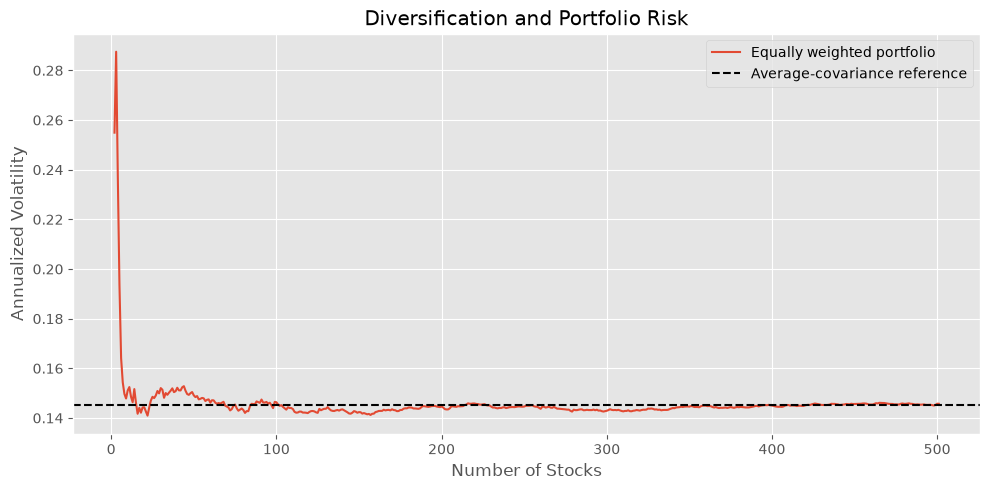

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(list(portfolio_sizes), volatilities, label="Equally weighted portfolio")
if np.isfinite(reference_volatility):
    plt.axhline(reference_volatility, color="black", linestyle="--",
                label="Average-covariance reference")
plt.title("Diversification and Portfolio Risk")
plt.xlabel("Number of Stocks")
plt.ylabel("Annualized Volatility")
plt.legend()
plt.tight_layout()
plt.show()

### 2.6 Focus on the first 50 portfolio sizes

Look at where the curve falls most sharply and whether volatility falls monotonically.

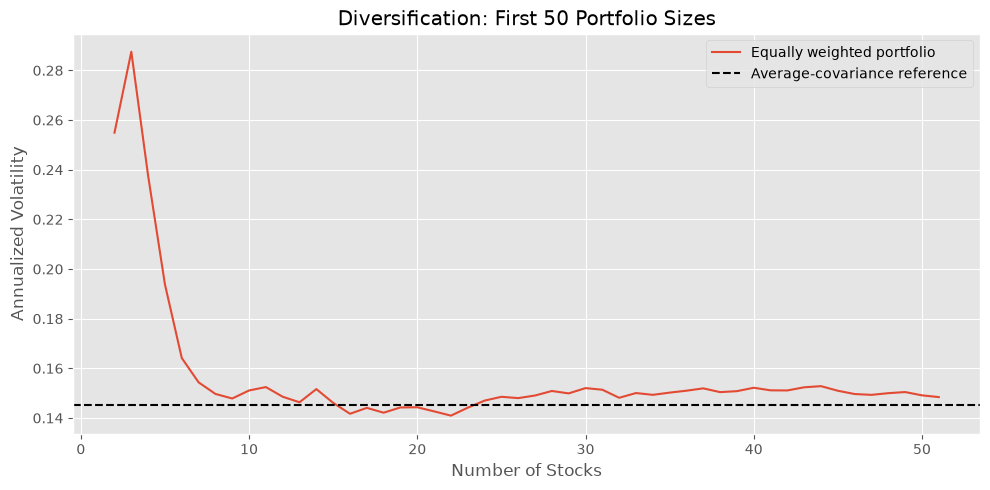

In [8]:
n_show = min(50, len(volatilities))
plt.figure(figsize=(10, 5))
plt.plot(list(portfolio_sizes)[:n_show], volatilities[:n_show],
         label="Equally weighted portfolio")
if np.isfinite(reference_volatility):
    plt.axhline(reference_volatility, color="black", linestyle="--",
                label="Average-covariance reference")
plt.title("Diversification: First 50 Portfolio Sizes")
plt.xlabel("Number of Stocks")
plt.ylabel("Annualized Volatility")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Conclusions and client recommendation

Based on your figures, write a short response to the client addressing these points:

- Does volatility generally decline as stocks are added? Can it sometimes rise after adding one more stock?
- Is the largest marginal reduction concentrated among smaller portfolios?
- Why does diversification have a limit when assets share common risks?
- Why does this particular historical dataset and stock order **not** establish the universally optimal number of stocks?

**Financial interpretation:** The benefits of diversification generally diminish, but their size depends on which stocks are added, their correlations, the period examined, and the portfolio weights. The average-covariance reference is not a direct proof of the exact level of market risk.

## 4. Additional concept — Contributions to return and risk

Asset $i$ contributes $w_i E[r_i]$ to expected portfolio return and $w_i\operatorname{Cov}(r_i,r_P)$ to **portfolio variance**. These variance contributions add up to portfolio variance.

Therefore, an asset's return contribution depends on its weight and expected return, while its risk contribution also depends on the other assets in the portfolio. An asset with negative covariance with the overall portfolio can reduce portfolio variance.

**Optional reflection:** Why can two stocks with similar standalone volatility have very different effects on the risk of a diversified portfolio?